In [1]:
from pathlib import Path
import sys, json, time, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier
import sklearn, xgboost

plt.rcParams.update({'figure.figsize': (9,4.8),'figure.dpi':110, 'axes.spines.top':False,
                     'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':0.19})
SEED=42
OUTPUT=Path('xgboost_v2_outputs'); OUTPUT.mkdir(exist_ok=True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__, 'pandas':pd.__version__,
          'scikit_learn':sklearn.__version__, 'xgboost':xgboost.__version__,
          'matplotlib':plt.matplotlib.__version__ if hasattr(plt,'matplotlib') else 'installed'}
print('VERIFIED ENVIRONMENT:',json.dumps(VERSIONS,indent=2))
print('XGBoost early stopping is configured in the constructor, not fit().')

VERIFIED ENVIRONMENT: {
  "python": "3.12.13",
  "numpy": "2.5.2",
  "pandas": "3.0.3",
  "scikit_learn": "1.7.2",
  "xgboost": "3.4.1",
  "matplotlib": "3.11.0"
}
XGBoost early stopping is configured in the constructor, not fit().


In [2]:
def generate_loan_data(n=20_000, seed=42, target_rate=0.24):
    rng=np.random.default_rng(seed)
    emi_income=np.clip(rng.beta(2.0, 4.2, n)*0.94 + 0.015, 0, 1)
    utilisation=np.clip(rng.beta(2.3, 2.2, n), 0, 1)
    prior_delays=rng.poisson(lam=0.48+1.05*(utilisation>0.75),size=n).astype(float)
    enquiries=rng.poisson(lam=1.0+.75*(utilisation>.68),size=n).astype(float)
    loan_tenure=rng.choice([12,24,36,48,60,72],size=n,p=[.1,.17,.24,.2,.18,.11]).astype(float)
    existing_loans=np.clip(rng.poisson(1.3,size=n),0,8).astype(float)
    balance_volatility=np.clip(rng.lognormal(mean=-1.,sigma=.6,size=n),0,3)
    savings_buffer=np.clip(rng.lognormal(mean=.2,sigma=.72,size=n),0,8)
    months_since_last_delinq=np.where(prior_delays>0,rng.integers(1,49,n),np.nan).astype(float)
    recently_late=(prior_delays>0)&(months_since_last_delinq<=9)

    # Risk is determined BEFORE observational masking; the simulator can 'know'
    # a true value that the eventual trained model does not observe.
    smooth=(.90*(emi_income-.35) + .85*(utilisation-.55)
            +.18*prior_delays + .10*enquiries + .10*existing_loans
            +.10*balance_volatility -.16*savings_buffer +.16*(loan_tenure>=60))
    nonlinear=(2.00*((emi_income>.40)&(utilisation>.77))
               +1.25*((prior_delays>=2)&(enquiries>=3))
               +1.05*((utilisation>.84)&(savings_buffer<.75))
               +.75*((balance_volatility>.65)&(existing_loans>=2))
               -.95*((prior_delays==0)&(savings_buffer>1.8))
               -.55*((emi_income<.21)&(savings_buffer>1.5))
               +.85*recently_late)
    z=smooth+nonlinear+rng.normal(0,.4,n)
    lo,hi=-8.,5.
    for _ in range(55):
        mid=(lo+hi)/2
        if expit(z+mid).mean()>target_rate:hi=mid
        else:lo=mid
    risk=expit(z+(lo+hi)/2)
    y=rng.binomial(1,risk).astype(int)
    X=pd.DataFrame({
        'emi_to_income':emi_income,'credit_utilisation':utilisation,
        'prior_delays':prior_delays,'credit_enquiries_6m':enquiries,
        'loan_tenure_months':loan_tenure,'existing_loans':existing_loans,
        'balance_volatility':balance_volatility,'savings_buffer_months':savings_buffer,
        'months_since_last_delinquency':months_since_last_delinq,
        'irrelevant_random':rng.normal(size=n)
    })
    injected=['credit_utilisation','balance_volatility','savings_buffer_months','credit_enquiries_6m']
    for col in injected:
        X.loc[rng.random(n)<.08,col]=np.nan
    # Important: derived features propagate missingness; no hidden clean backup.
    X['utilisation_redundant']=np.clip(X['credit_utilisation']*.93+rng.normal(0,.04,n),0,1)
    X['small_balance_ratio']=np.clip(X['balance_volatility']/(X['savings_buffer_months']+1),0,4)
    assert X.loc[X['credit_utilisation'].isna(),'utilisation_redundant'].isna().all()
    assert X.loc[X['balance_volatility'].isna(),'small_balance_ratio'].isna().all()
    return X,pd.Series(y,name='default'),injected

X,y,injected_cols=generate_loan_data(seed=SEED)
idx_train,idx_tmp=train_test_split(np.arange(len(y)),train_size=.6,stratify=y,random_state=SEED)
idx_val,idx_test=train_test_split(idx_tmp,test_size=.5,stratify=y.iloc[idx_tmp],random_state=SEED)
X_train,y_train=X.iloc[idx_train].copy(),y.iloc[idx_train].copy()
X_val,y_val=X.iloc[idx_val].copy(),y.iloc[idx_val].copy()
assert not(set(idx_train)&set(idx_val) or set(idx_train)&set(idx_test) or set(idx_val)&set(idx_test))
assert (len(idx_train),len(idx_val),len(idx_test))==(12000,4000,4000)
assert .19<y.mean()<.29
assert X_train.isna().any().any()
assert (X_train.loc[X_train['prior_delays']==0,'months_since_last_delinquency'].isna()).all()
print(f'Rows: {len(X):,} | observed simulated default rate: {y.mean():.2%} | features: {X.shape[1]}')
print('Split sizes:',len(idx_train),len(idx_val),len(idx_test))
print('Fraction missing by feature:')
print((X_train.isna().mean()*100).round(1).to_string())

Rows: 20,000 | observed simulated default rate: 24.30% | features: 12
Split sizes: 12000 4000 4000
Fraction missing by feature:
emi_to_income                     0.0
credit_utilisation                8.7
prior_delays                      0.0
credit_enquiries_6m               8.0
loan_tenure_months                0.0
existing_loans                    0.0
balance_volatility                7.8
savings_buffer_months             8.5
months_since_last_delinquency    56.7
irrelevant_random                 0.0
utilisation_redundant             8.7
small_balance_ratio              15.5


In [3]:
print(X_train.shape)

(12000, 12)


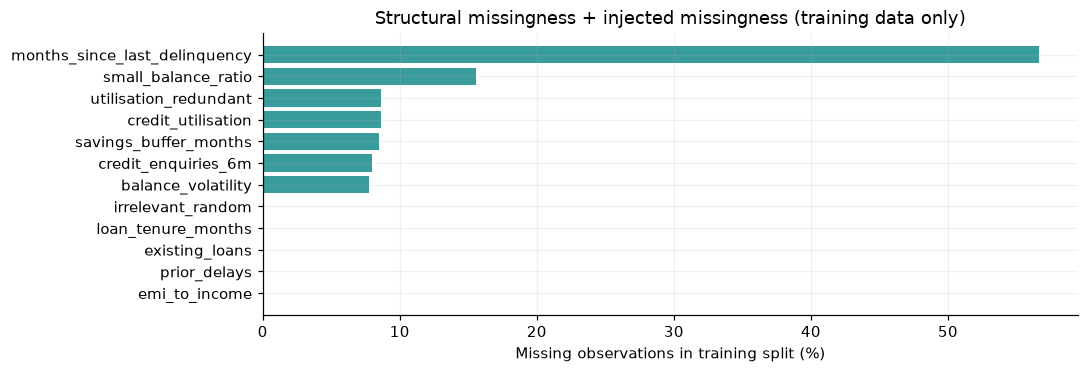

In [4]:
fig,ax=plt.subplots(figsize=(10,3.5))
missing=(X_train.isna().mean()*100).sort_values(ascending=True)
ax.barh(missing.index,missing.values,color='#399c9c')
ax.set_xlabel('Missing observations in training split (%)')
ax.set_title('Structural missingness + injected missingness (training data only)')
plt.tight_layout()
plt.show()

In [5]:
X_train

,emi_to_income,credit_utilisation,prior_delays,credit_enquiries_6m,loan_tenure_months,existing_loans,balance_volatility,savings_buffer_months,months_since_last_delinquency,irrelevant_random,utilisation_redundant,small_balance_ratio
15828,0.402711,0.369958,0.0,0.0,72.0,1.0,0.102099,0.841516,NaN,0.152647,0.374473,0.055443
17181,0.259875,0.475259,1.0,2.0,48.0,1.0,0.235692,0.214621,31.0,0.226427,0.468838,0.194046
12982,0.609583,0.493572,1.0,0.0,60.0,1.0,0.227816,1.272699,30.0,0.896200,0.428830,0.100240
9985,0.343830,0.521645,0.0,0.0,72.0,1.0,0.565190,1.814327,NaN,0.633820,0.536409,0.200826
16637,0.203256,0.840891,2.0,2.0,48.0,3.0,0.189951,0.702668,41.0,-0.164281,0.788809,0.111561
...,...,...,...,...,...,...,...,...,...,...,...,...
15041,0.156074,0.511446,1.0,1.0,24.0,1.0,0.450553,1.219165,3.0,0.036976,0.504185,0.203028
17134,0.667928,0.851994,1.0,0.0,72.0,1.0,0.448388,0.931132,10.0,0.861468,0.744401,0.232189
11003,0.181617,0.770844,5.0,2.0,12.0,4.0,0.123320,1.221273,20.0,-1.079234,0.764727,0.055518
2715,0.078144,0.626853,1.0,NaN,36.0,1.0,0.184110,0.269438,15.0,-0.906327,0.618812,0.145033


In [7]:
X_train['months_since_last_delinquency'].isna().sum()

np.int64(6799)

In [13]:
IMP = SimpleImputer(strategy = 'median', add_indicator=True)

Xt = IMP.fit_transform(X_train)
Xv = IMP.transform(X_val)


np.isnan(Xt).sum()
np.isnan(Xv).sum()

np.int64(0)

In [17]:
def benchmark_models(seed = 42, round = 160):
    return {
        "LogisticRegression": LogisticRegression(max_iter = 2000, random_state = SEED),
        "Random_forest_depth3": RandomForestClassifier(n_estimators=round,
                                                       max_depth = 3, random_state=SEED),
        'GradientBoosting_exact': GradientBoostingClassifier(
            n_estimators=round, learning_rate=0.1, max_depth=3, random_state=SEED
        ),
        'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=round, learning_rate=0.1,
                                                               max_leaf_nodes=8, max_bins = 255,
                                                               l2_regularization=0),
        'XGBoost_hist': XGBClassifier(n_estimators = round, learning_rate = 0.1,
                                      max_depth = 3, tree_method = 'hist', max_bin = 256,
                                      n_jobs = 1,
                                      eval_metrics = 'log_loss', random_state = SEED)

                                                    
    }

BENCHMARK = {}
validation_baseline = {}

with threadpool_limits(limits = 1):
    for name, model in benchmark_models().items():
        times = []
        for _ in range(3):
            tick = time.perf_counter()
            model.fit(Xt, y_train)
            times.append(time.perf_counter() - tick)
        val_prob = model.predict_proba(Xv)[:,1]
        fit_rounds = int(model.n_iter_) if name == 'HistGradientBoosting' else(int(model.n_estimators) if hasattr(model, 'n_estimators') else None)
        
        BENCHMARK[name] = {'seconds_median': float(np.median(times)),
                           'validation_auc': float(roc_auc_score(y_val, val_prob)),
                           'rounds': fit_rounds, 'seconds_trials': list(map(float, times))}
        validation_baseline[name] = val_prob

bench_df = pd.DataFrame(BENCHMARK).T[['validation_auc', 'seconds_median', 'rounds']]
print(bench_df.round(4).to_string())




c:\Users\AIML\miniconda3\envs\aiml\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:13:14] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


                       validation_auc seconds_median rounds
LogisticRegression           0.702086       0.303599   None
Random_forest_depth3         0.699696       1.658384    160
GradientBoosting_exact       0.714716        8.91617    160
HistGradientBoosting         0.715708       0.207667     70
XGBoost_hist                 0.716342       0.224794    160


<BarContainer object of 5 artists>

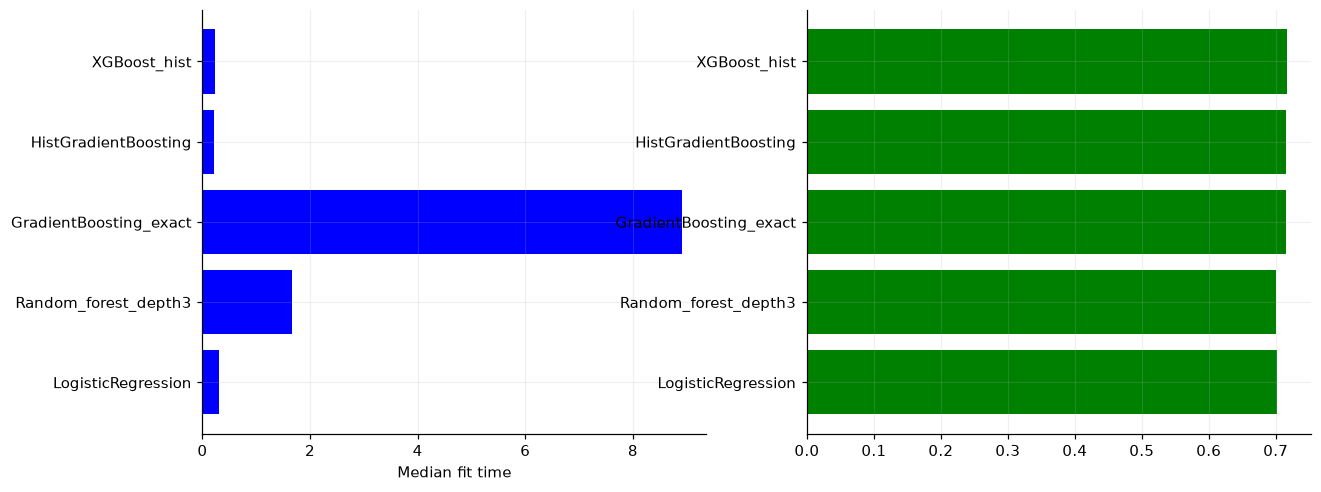

In [21]:
fig, axs = plt.subplots(1,2, figsize = (13, 5))
labels = list(BENCHMARK)
axs[0].barh(labels, [BENCHMARK[k]['seconds_median'] for k in labels], color = 'blue')
axs[0].set_xlabel("Median fit time")
axs[1].barh(labels, [BENCHMARK[k]['validation_auc'] for k in labels], color='green')


In [24]:
methods = ['exact', 'hist']
METHODS_COMPARE = {}
for method in methods:
    clf = XGBClassifier(n_estimators = 160, max_depth = 3, learning_rate = .1, tree_method = method,
                        n_jobs = 3, random_state = SEED, eval_metrics = 'logloss')
    trials = []
    for _ in range(3):
        t0 = time.perf_counter()
        clf.fit(Xt, y_train)
        trials.append(time.perf_counter() - t0)
    METHODS_COMPARE[method] = {'seconds_median': float(np.median(trials)),
                               'seconds_trial': list(map(float, trials)), 'rounds': int(clf.n_estimators),
                               'val_auc': float(roc_auc_score(y_val, clf.predict_proba(Xv)[:,1]))}

print(pd.DataFrame(METHODS_COMPARE).T[['seconds_median', 'rounds', 'val_auc']].to_string())

    


c:\Users\AIML\miniconda3\envs\aiml\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:33:20] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\AIML\miniconda3\envs\aiml\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:33:21] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\AIML\miniconda3\envs\aiml\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:33:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
c:\Users\AIML\miniconda3\envs\aiml\Lib\site-packages\xgboost\training.py:200: UserWarning: [14:33:23] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "eval_metrics" } are not use

      seconds_median rounds   val_auc
exact       0.937723    160  0.716165
hist        0.138266    160  0.716342


In [26]:
-np.log(0.2)

np.float64(1.6094379124341003)

In [27]:
y_toy=np.array([0.,0.,1.,1.,1.,0.,0.,1.])
p_toy=np.array([.24,.28,.34,.45,.56,.61,.72,.79])
g=p_toy-y_toy
h=p_toy*(1-p_toy)
toy_utilisation=np.array([.12,.22,.31,.44,.56,.66,.82,.93])
left=np.flatnonzero(toy_utilisation<.50); right=np.flatnonzero(toy_utilisation>=.50)
GL,HL=g[left].sum(),h[left].sum()
GR,HR=g[right].sum(),h[right].sum()

def leaf_weight(G,H,lam):return -G/(H+lam)
def split_gain(lam=0.,gamma=0.):
    parent_G,parent_H=GL+GR,HL+HR
    return .5*(GL**2/(HL+lam)+GR**2/(HR+lam)-parent_G**2/(parent_H+lam))-gamma

math_rows=[]
for lam in [0.,1.,5.,20.]:
    for gamma in [0.,.1,.5]:
        math_rows.append({'lambda':lam,'gamma':gamma,'left_leaf_weight':leaf_weight(GL,HL,lam),
                          'gain':split_gain(lam,gamma),'accept_split':split_gain(lam,gamma)>0})
math_df=pd.DataFrame(math_rows)
print('Toy gradient sum:',round(float(GL+GR),4),'Toy Hessian sum:',round(float(HL+HR),4))
print(math_df.round(4).to_string(index=False))
assert np.all(h>0)
print(f'Candidate split: utilisation < 0.50 | left H={HL:.3f}, right H={HR:.3f}')
print('Default min_child_weight=1 would reject this split:',min(HL,HR)<1)
assert min(HL,HR)<1 and min(HL,HR)>.5
assert np.isclose(split_gain(0,.5),split_gain(0,0)-.5)
assert abs(leaf_weight(GL,HL,20))<abs(leaf_weight(GL,HL,0))

Toy gradient sum: -0.01 Toy Hessian sum: 1.7077
 lambda  gamma  left_leaf_weight    gain  accept_split
    0.0    0.0            0.8062  0.5495          True
    0.0    0.1            0.8062  0.4495          True
    0.0    0.5            0.8062  0.0495          True
    1.0    0.0            0.3718  0.2531          True
    1.0    0.1            0.3718  0.1531          True
    1.0    0.5            0.3718 -0.2469         False
    5.0    0.0            0.1178  0.0802          True
    5.0    0.1            0.1178 -0.0198         False
    5.0    0.5            0.1178 -0.4198         False
   20.0    0.0            0.0331  0.0225          True
   20.0    0.1            0.0331 -0.0775         False
   20.0    0.5            0.0331 -0.4775         False
Candidate split: utilisation < 0.50 | left H=0.856, right H=0.852
Default min_child_weight=1 would reject this split: True


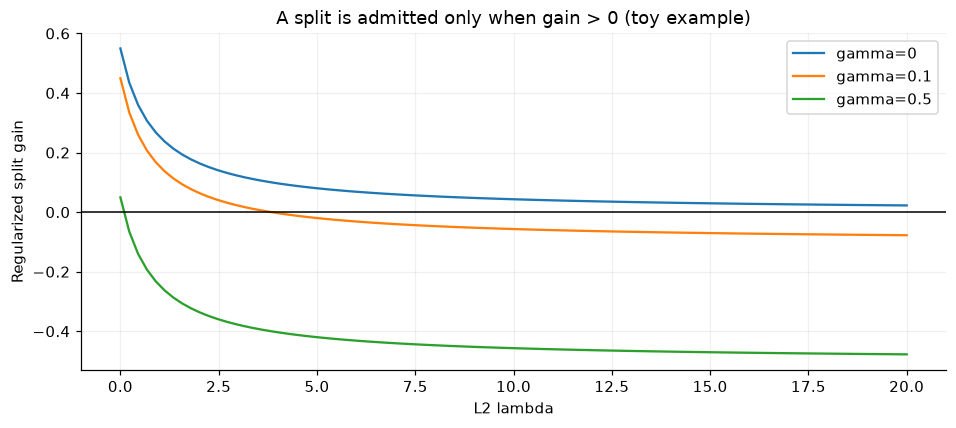

In [28]:
fig,ax=plt.subplots(figsize=(8.8,4))
lambdas=np.linspace(0,20,90)
for gamma in [0,.1,.5]:ax.plot(lambdas,[split_gain(v,gamma) for v in lambdas],label=f'gamma={gamma:g}')
ax.axhline(0,color='black',lw=1);ax.set_xlabel('L2 lambda');ax.set_ylabel('Regularized split gain')
ax.set_title('A split is admitted only when gain > 0 (toy example)');ax.legend()
plt.tight_layout();fig.savefig(OUTPUT/'03_split_gain.png',dpi=160);plt.show()

 bin  left_edge  right_edge  G_sum  H_sum
   0       0.00        0.25   0.52 0.3840
   1       0.25        0.50  -1.21 0.4719
   2       0.50        0.75   0.17 0.4843
   3       0.75        1.01   0.51 0.3675


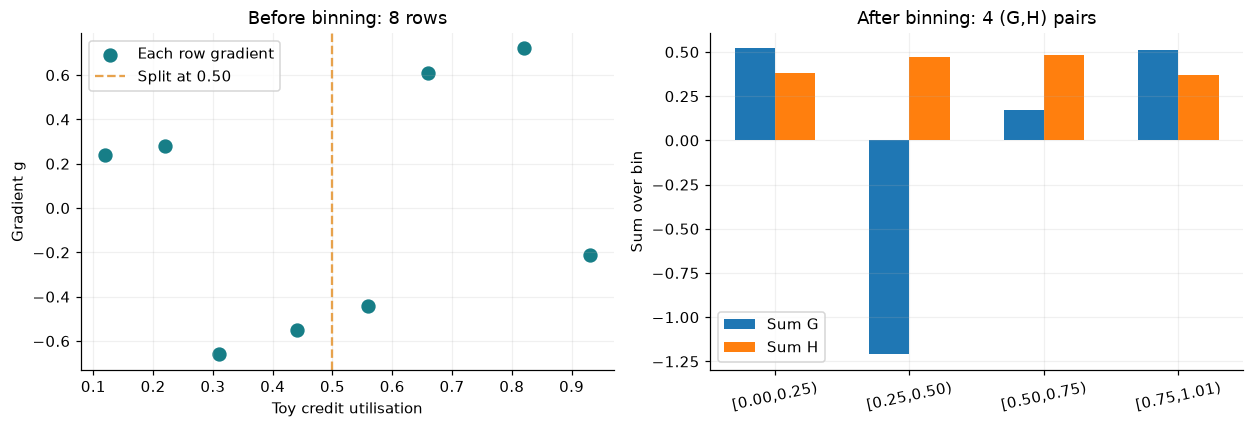

In [29]:
# Demonstrate how a histogram condenses sample-level (g, h) to per-bin totals.
# Four bins, four candidate boundaries; use fixed bins for pedagogical clarity.
BIN_EDGES=np.array([0,.25,.50,.75,1.01])
bin_ids=np.digitize(toy_utilisation,BIN_EDGES[1:-1],right=False)
G_BINS=np.bincount(bin_ids,weights=g,minlength=4)
H_BINS=np.bincount(bin_ids,weights=h,minlength=4)
hist_table=pd.DataFrame({'bin':range(4),'left_edge':BIN_EDGES[:-1],
                         'right_edge':BIN_EDGES[1:],'G_sum':G_BINS,'H_sum':H_BINS})
print(hist_table.round(4).to_string(index=False))
assert np.isclose(G_BINS[:2].sum(),GL) and np.isclose(H_BINS[:2].sum(),HL)
fig,axs=plt.subplots(1,2,figsize=(11.5,4))
axs[0].scatter(toy_utilisation,g,c='#177e87',s=70,label='Each row gradient')
axs[0].axvline(.5,color='#e7a24c',ls='--',label='Split at 0.50')
axs[0].set(xlabel='Toy credit utilisation',ylabel='Gradient g',title='Before binning: 8 rows')
axs[0].legend()
axs[1].bar(np.arange(4)-0.15,G_BINS,width=.3,label='Sum G')
axs[1].bar(np.arange(4)+0.15,H_BINS,width=.3,label='Sum H')
axs[1].set_xticks(range(4),[f'[{BIN_EDGES[i]:.2f},{BIN_EDGES[i+1]:.2f})' for i in range(4)],rotation=12)
axs[1].set(ylabel='Sum over bin',title='After binning: 4 (G,H) pairs')
axs[1].legend();plt.tight_layout()
fig.savefig(OUTPUT/'09_histogram_binning.png',dpi=160);plt.show()

In [30]:
try:
    GradientBoostingClassifier(n_estimators=10,random_state=SEED).fit(X_train,y_train)
except ValueError as exc:
    print('EXPECTED FAILURE (classic GB):',str(exc).splitlines()[0])
    assert 'NaN' in str(exc) or 'nan' in str(exc).lower()
else:raise AssertionError('Expected classic GB to reject NaNs on sklearn 1.8')

missing_models={
 'ClassicGB + imputer/indicator':make_pipeline(SimpleImputer(strategy='median',add_indicator=True),
                           GradientBoostingClassifier(n_estimators=120,learning_rate=.1,max_depth=3,random_state=SEED)),
 'HistGB native':HistGradientBoostingClassifier(max_iter=120,learning_rate=.1,max_leaf_nodes=8,early_stopping=False,random_state=SEED),
 'XGBoost native':XGBClassifier(n_estimators=120,learning_rate=.1,max_depth=3,n_jobs=1,tree_method='hist',
                               eval_metric='logloss',random_state=SEED)}
MISSING_RESULTS={}
with threadpool_limits(limits=1):
    for name,clf in missing_models.items():
        clf.fit(X_train,y_train)
        p=clf.predict_proba(X_val)[:,1]
        MISSING_RESULTS[name]=float(roc_auc_score(y_val,p))
print('Validation ROC-AUC under honest missing-value handling:')
print(pd.Series(MISSING_RESULTS).round(4).to_string())
assert all(.5<=v<=1 for v in MISSING_RESULTS.values())

EXPECTED FAILURE (classic GB): Input X contains NaN.
Validation ROC-AUC under honest missing-value handling:
ClassicGB + imputer/indicator    0.7146
HistGB native                    0.7106
XGBoost native                   0.7141


In [33]:
AGGRESSIVE_PARAMS=dict(n_estimators=550,max_depth=10,learning_rate=.24,
                       subsample=1,colsample_bytree=1,reg_lambda=0,reg_alpha=0,
                       min_child_weight=1,tree_method='hist',n_jobs=1,random_state=SEED,
                       eval_metric='logloss')
with threadpool_limits(limits=1):
    aggressive=XGBClassifier(**AGGRESSIVE_PARAMS)
    aggressive.fit(X_train,y_train,eval_set=[(X_train,y_train),(X_val,y_val)],verbose=False)
curve=aggressive.evals_result()
train_loss=np.array(curve['validation_0']['logloss'])
val_loss=np.array(curve['validation_1']['logloss'])
optimal_iteration=int(np.argmin(val_loss))
print(f'Aggressive: best validation iteration {optimal_iteration+1}, '
      f'best log-loss {val_loss.min():.4f}, last log-loss {val_loss[-1]:.4f}')
assert len(val_loss)==AGGRESSIVE_PARAMS['n_estimators']
assert np.isfinite(val_loss).all() and np.isfinite(train_loss).all()
# A true *observed* outcome is reported; never manufacture a threshold crossing.
OVERFIT={'best_round':optimal_iteration+1,'best_val_logloss':float(val_loss.min()),
         'final_val_logloss':float(val_loss[-1]),'final_train_logloss':float(train_loss[-1]),
         'increase_pct':float((val_loss[-1]/val_loss.min()-1)*100)}
assert optimal_iteration < len(val_loss)-20, 'Overfitting too weak for live demo: adjust generator in development, not test'
assert OVERFIT['increase_pct']>1.0,'Validation loss did not worsen enough for a clear demo'

Aggressive: best validation iteration 4, best log-loss 0.5155, last log-loss 0.9018


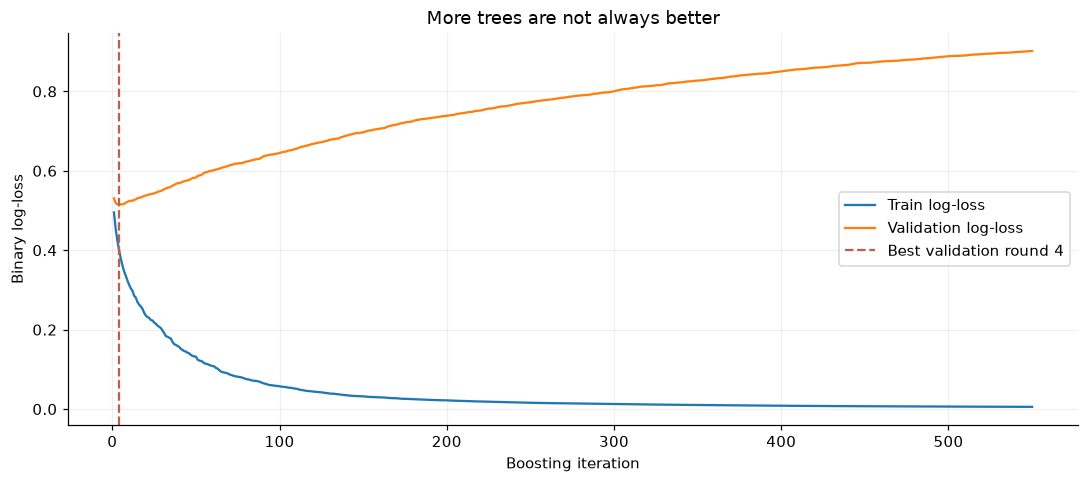

In [34]:
fig,ax=plt.subplots(figsize=(10,4.5))
ax.plot(np.arange(1,len(train_loss)+1),train_loss,label='Train log-loss')
ax.plot(np.arange(1,len(val_loss)+1),val_loss,label='Validation log-loss')
ax.axvline(optimal_iteration+1,ls='--',color='#ba604e',label=f'Best validation round {optimal_iteration+1}')
ax.set_xlabel('Boosting iteration');ax.set_ylabel('Binary log-loss');ax.set_title('More trees are not always better')
ax.legend();plt.tight_layout();fig.savefig(OUTPUT/'04_overfitting.png',dpi=160);plt.show()

In [47]:
with threadpool_limits(limits=1):
    stopped=XGBClassifier(n_estimators=1500,max_depth=3,learning_rate=.12,subsample=.9,
                          colsample_bytree=.9,reg_lambda=0,min_child_weight=3,
                          tree_method='hist',n_jobs=1,random_state=SEED,
                          eval_metric='logloss',early_stopping_rounds=100)
    stopped.fit(X_train,y_train,eval_set=[(X_train,y_train),(X_val,y_val)],verbose=False)
stop_history=stopped.evals_result()
stop_built=len(stop_history['validation_1']['logloss'])
STOPPING={'best_iteration_1based':int(stopped.best_iteration+1),'trees_built':int(stop_built),
          'max_estimators':1500,'validation_logloss_best':float(stopped.best_score)}
print(STOPPING)
assert 0<stopped.best_iteration+1<=stop_built<=1500
assert stop_built<1500,'Expected early stop before the estimator limit'
assert np.isclose(stopped.best_score,min(stop_history['validation_1']['logloss']),rtol=1e-6)

{'best_iteration_1based': 46, 'trees_built': 146, 'max_estimators': 1500, 'validation_logloss_best': 0.4877668171217665}


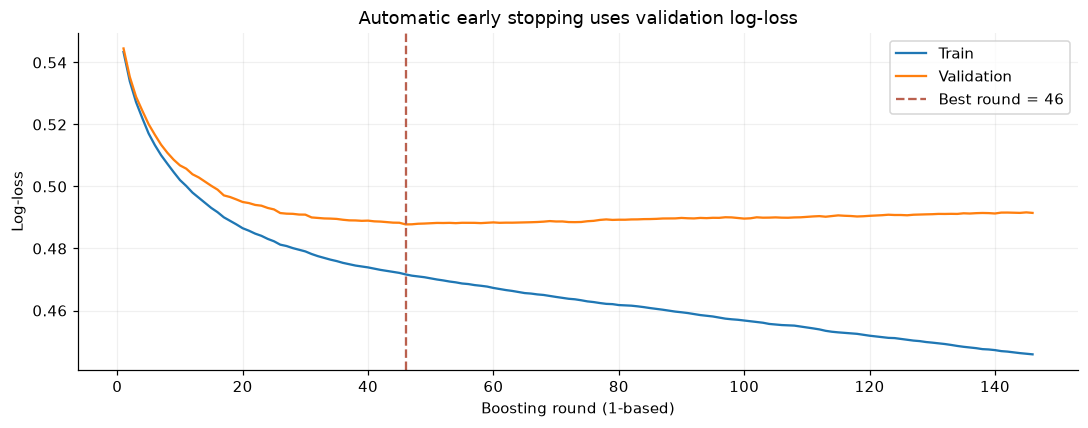

In [48]:
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(np.arange(1,stop_built+1),stop_history['validation_0']['logloss'],label='Train')
ax.plot(np.arange(1,stop_built+1),stop_history['validation_1']['logloss'],label='Validation')
ax.axvline(stopped.best_iteration+1,color='#ba604e',ls='--',label=f'Best round = {stopped.best_iteration+1}')
ax.set_xlabel('Boosting round (1-based)');ax.set_ylabel('Log-loss')
ax.set_title('Automatic early stopping uses validation log-loss');ax.legend()
plt.tight_layout();fig.savefig(OUTPUT/'05_early_stopping.png',dpi=160);plt.show()

In [49]:
BASE=dict(n_estimators=260,learning_rate=.10,max_depth=5,min_child_weight=2,
          subsample=.9,colsample_bytree=.9,reg_alpha=0,reg_lambda=1,
          gamma=0,tree_method='hist',n_jobs=1,eval_metric='logloss',random_state=SEED)
TUNING_ROWS=[]
experiment_grid={
 'reg_lambda':[0,1,8,30], 'gamma':[0,.5,2,8], 'reg_alpha':[0,.5,3,10],
 'max_depth':[2,4,7], 'subsample':[.65,.85,1.0], 'colsample_bytree':[.50,.75,1.0]}
with threadpool_limits(limits=1):
    for param,values in experiment_grid.items():
        for value in values:
            args={**BASE,param:value}
            m=XGBClassifier(**args);m.fit(X_train,y_train)
            a=roc_auc_score(y_train,m.predict_proba(X_train)[:,1])
            v=roc_auc_score(y_val,m.predict_proba(X_val)[:,1])
            TUNING_ROWS.append({'parameter':param,'value':float(value),'train_auc':float(a),
                                'val_auc':float(v),'train_val_gap':float(a-v)})
tuning_df=pd.DataFrame(TUNING_ROWS)
print(tuning_df.round(4).to_string(index=False))
assert len(tuning_df)==sum(len(k) for k in experiment_grid.values())

       parameter  value  train_auc  val_auc  train_val_gap
      reg_lambda   0.00     0.9409   0.6999         0.2410
      reg_lambda   1.00     0.9340   0.6959         0.2381
      reg_lambda   8.00     0.9031   0.7038         0.1992
      reg_lambda  30.00     0.8714   0.7072         0.1642
           gamma   0.00     0.9340   0.6959         0.2381
           gamma   0.50     0.9308   0.6957         0.2351
           gamma   2.00     0.8519   0.7116         0.1403
           gamma   8.00     0.7539   0.7173         0.0366
       reg_alpha   0.00     0.9340   0.6959         0.2381
       reg_alpha   0.50     0.9359   0.6979         0.2380
       reg_alpha   3.00     0.9196   0.7005         0.2192
       reg_alpha  10.00     0.8591   0.7065         0.1526
       max_depth   2.00     0.7600   0.7163         0.0437
       max_depth   4.00     0.8713   0.7038         0.1675
       max_depth   7.00     0.9954   0.6789         0.3165
       subsample   0.65     0.9301   0.6894         0.24

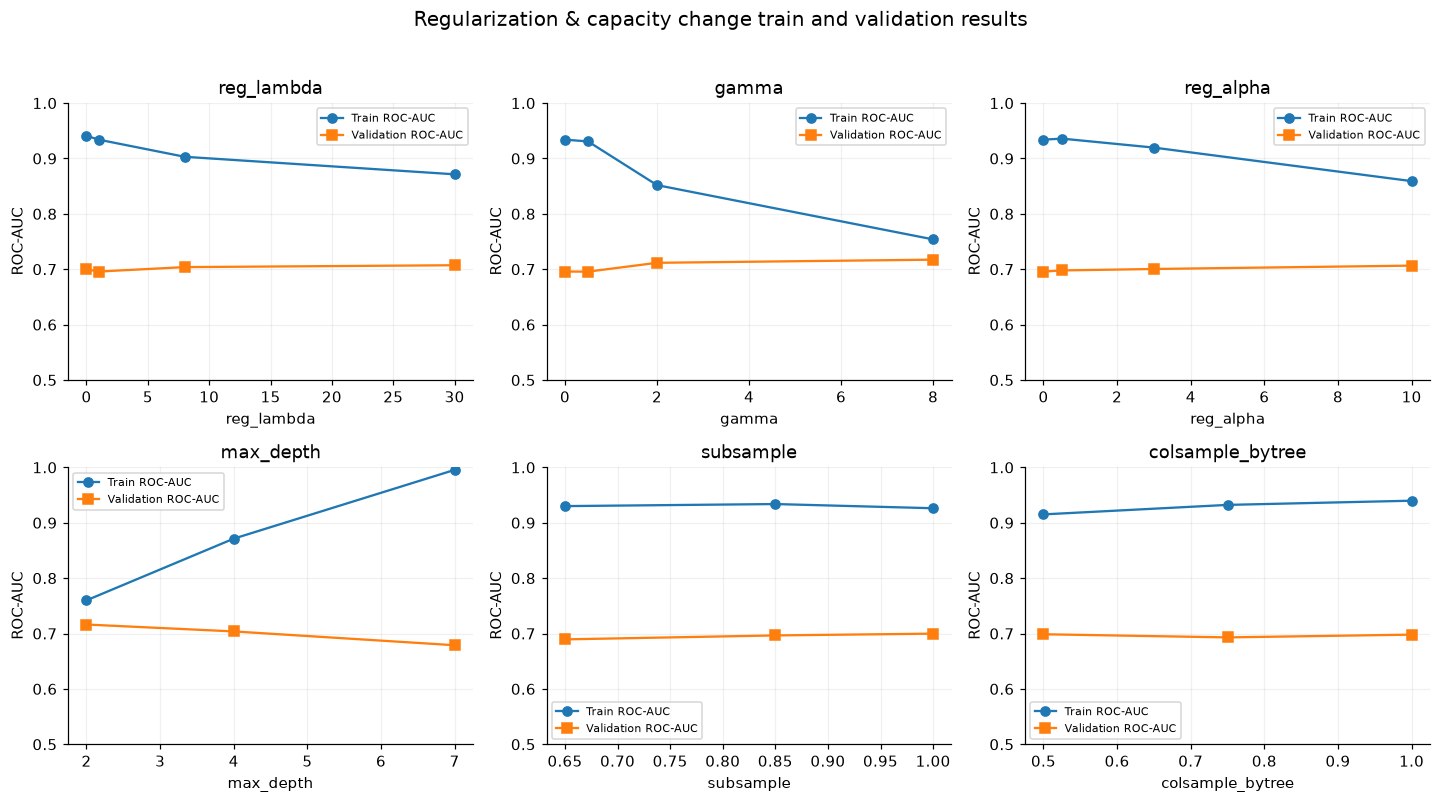

In [50]:
fig,axs=plt.subplots(2,3,figsize=(13.2,7.4))
for ax,(name,group) in zip(axs.flat,tuning_df.groupby('parameter',sort=False)):
    g=group.sort_values('value')
    ax.plot(g['value'],g['train_auc'],'o-',label='Train ROC-AUC')
    ax.plot(g['value'],g['val_auc'],'s-',label='Validation ROC-AUC')
    ax.set_title(name);ax.set_xlabel(name);ax.set_ylabel('ROC-AUC')
    ax.set_ylim(.5,1);ax.legend(fontsize=7)
fig.suptitle('Regularization & capacity change train and validation results',fontsize=13)
plt.tight_layout(rect=[0,0,1,.96]);fig.savefig(OUTPUT/'06_regularization.png',dpi=160);plt.show()

In [51]:
CANDIDATES=[
    {'max_depth':2,'gamma':2.,'reg_lambda':8.,'min_child_weight':2},
    {'max_depth':3,'gamma':2.,'reg_lambda':8.,'min_child_weight':2},
    {'max_depth':3,'gamma':8.,'reg_lambda':8.,'min_child_weight':2},
    {'max_depth':4,'gamma':2.,'reg_lambda':8.,'min_child_weight':2},
]
selected_rows=[]
with threadpool_limits(limits=1):
    for i,choice in enumerate(CANDIDATES):
        config=dict(n_estimators=900,learning_rate=.08,subsample=.90,
                    colsample_bytree=.75,reg_alpha=.5,tree_method='hist',
                    n_jobs=1,random_state=SEED,eval_metric='logloss',
                    early_stopping_rounds=35,**choice)
        model=XGBClassifier(**config)
        model.fit(X_train,y_train,eval_set=[(X_train,y_train),(X_val,y_val)],verbose=False)
        valp=model.predict_proba(X_val)[:,1]
        selected_rows.append({'candidate':i+1,'depth':choice['max_depth'],
            'gamma':choice['gamma'],'lambda':choice['reg_lambda'],
            'best_round':int(model.best_iteration+1),
            'val_auc':float(roc_auc_score(y_val,valp)),
            'val_logloss':float(log_loss(y_val,valp)),
            'chosen_params':config})
# Deterministic tie-break: higher AUC, lower log loss, shallower depth.
SELECTED=sorted(selected_rows,key=lambda r:(-r['val_auc'],r['val_logloss'],r['depth']))[0]
XGB_FINAL_PARAMS={k:v for k,v in SELECTED['chosen_params'].items() if k!='early_stopping_rounds'}
XGB_FINAL_PARAMS['n_estimators']=SELECTED['best_round']
selection_table=pd.DataFrame(selected_rows).drop(columns=['chosen_params'])
print('Frozen XGBoost configurations (validation-only selection):')
print(selection_table.round(4).to_string(index=False))
print('SELECTED:',{k:SELECTED[k] for k in ['candidate','depth','gamma','lambda','best_round','val_auc','val_logloss']})
assert SELECTED['best_round']<900 and XGB_FINAL_PARAMS['n_estimators']>0
assert all(np.isfinite(r['val_auc']) for r in selected_rows)
assert XGB_FINAL_PARAMS['max_depth'] in [2,3,4]

Frozen XGBoost configurations (validation-only selection):
 candidate  depth  gamma  lambda  best_round  val_auc  val_logloss
         1      2    2.0     8.0         141   0.7204       0.4869
         2      3    2.0     8.0         109   0.7181       0.4878
         3      3    8.0     8.0         226   0.7187       0.4884
         4      4    2.0     8.0         101   0.7181       0.4878
SELECTED: {'candidate': 1, 'depth': 2, 'gamma': 2.0, 'lambda': 8.0, 'best_round': 141, 'val_auc': 0.7204469532647281, 'val_logloss': 0.48692403918881805}


In [53]:
dev_idx=np.concatenate([idx_train,idx_val])
X_dev,y_dev=X.iloc[dev_idx].copy(),y.iloc[dev_idx].copy()
SEEDS=[11,22,33,44,55]
VARIABILITY=[]
with threadpool_limits(limits=1):
    for seed in SEEDS:
        tr,va=train_test_split(np.arange(len(X_dev)),test_size=.25,stratify=y_dev,random_state=seed)
        Xdt,Xdv=X_dev.iloc[tr],X_dev.iloc[va]
        ydt,ydv=y_dev.iloc[tr],y_dev.iloc[va]
        imp=SimpleImputer(strategy='median',add_indicator=True)
        train_matrix,val_matrix=imp.fit_transform(Xdt),imp.transform(Xdv)
        models=benchmark_models(seed=seed,round=160)
        models['XGBoost_hist']=XGBClassifier(**{**XGB_FINAL_PARAMS,'random_state':seed})
        for name,m in models.items():
            m.fit(train_matrix,ydt)
            auc=roc_auc_score(ydv,m.predict_proba(val_matrix)[:,1])
            VARIABILITY.append({'seed':seed,'model':name,'roc_auc':float(auc)})
variability=pd.DataFrame(VARIABILITY)
var_table=variability.groupby('model')['roc_auc'].agg(['mean','std']).sort_values('mean',ascending=False)
print('Five-development-split ROC-AUC (descriptive variability):')
print(var_table.round(4).to_string())
wide=variability.pivot(index='seed',columns='model',values='roc_auc')
paired=wide['XGBoost_hist']-wide['HistGradientBoosting']
print('Paired development AUC difference XGBoost - HistGB:',np.round(paired.values,4),
      'mean:',round(float(paired.mean()),4))
assert len(variability)==25 and len(wide)==5
assert wide.notna().all().all()

Five-development-split ROC-AUC (descriptive variability):
                          mean     std
model                                 
XGBoost_hist            0.7191  0.0059
HistGradientBoosting    0.7149  0.0074
GradientBoosting_exact  0.7135  0.0051
Random_forest_depth3    0.6992  0.0069
LogisticRegression      0.6947  0.0043
Paired development AUC difference XGBoost - HistGB: [0.0072 0.0046 0.0002 0.0029 0.0061] mean: 0.0042


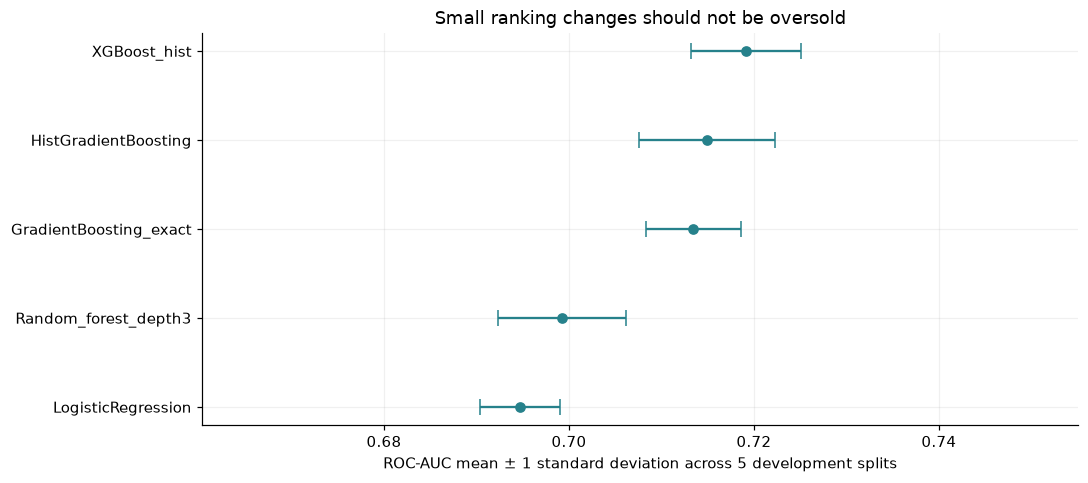

In [54]:
fig,ax=plt.subplots(figsize=(10,4.5))
ordered=var_table.sort_values('mean')
ax.errorbar(ordered['mean'],ordered.index,xerr=ordered['std'],fmt='o',capsize=5,color='#26818b')
ax.set_xlim(max(.5,float((ordered['mean']-ordered['std']).min())-.03),
            min(1.,float((ordered['mean']+ordered['std']).max())+.03))
ax.set_xlabel('ROC-AUC mean ± 1 standard deviation across 5 development splits')
ax.set_title('Small ranking changes should not be oversold')
plt.tight_layout();fig.savefig(OUTPUT/'07_development_uncertainty.png',dpi=160);plt.show()

In [55]:
# The ONLY notebook cell that opens sealed test observations/labels.
X_test,y_test=X.iloc[idx_test].copy(),y.iloc[idx_test].copy()
# All models get exactly the same 80% development records for final fitting.
X_dev,y_dev=X.iloc[np.concatenate([idx_train,idx_val])].copy(),y.iloc[np.concatenate([idx_train,idx_val])].copy()
final_models={
  'LogisticRegression':make_pipeline(SimpleImputer(strategy='median',add_indicator=True),
                                     LogisticRegression(max_iter=2000,random_state=SEED)),
  'RandomForest_depth3':make_pipeline(SimpleImputer(strategy='median',add_indicator=True),
                    RandomForestClassifier(n_estimators=160,max_depth=3,n_jobs=1,random_state=SEED)),
  'GradientBoosting_exact':make_pipeline(SimpleImputer(strategy='median',add_indicator=True),
                    GradientBoostingClassifier(n_estimators=160,learning_rate=.1,max_depth=3,random_state=SEED)),
  'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=160,learning_rate=.1,
                    max_leaf_nodes=8,early_stopping=False,random_state=SEED),
  'XGBoost_hist':XGBClassifier(**XGB_FINAL_PARAMS)
}
TEST_RESULTS={};TEST_PROBS={}
with threadpool_limits(limits=1):
    for name,model in final_models.items():
        model.fit(X_dev,y_dev)
        pred=model.predict_proba(X_test)[:,1]
        TEST_PROBS[name]=pred
        TEST_RESULTS[name]={'test_roc_auc':float(roc_auc_score(y_test,pred)),
                            'test_average_precision':float(average_precision_score(y_test,pred)),
                            'test_logloss':float(log_loss(y_test,pred)),
                            'trained_on_dev_rows':int(len(X_dev))}
final_table=pd.DataFrame(TEST_RESULTS).T.sort_values('test_roc_auc',ascending=False)
print('FINAL TEST: frozen specifications; all models trained on 80% development; NO further tuning.')
print(final_table.to_string(float_format=lambda v:f'{v:.4f}'))
assert len(X_dev)==16000 and len(X_test)==4000
assert all(0<=v['test_roc_auc']<=1 for v in TEST_RESULTS.values())
assert all(np.isfinite(v['test_logloss']) for v in TEST_RESULTS.values())

FINAL TEST: frozen specifications; all models trained on 80% development; NO further tuning.
                        test_roc_auc  test_average_precision  test_logloss  trained_on_dev_rows
XGBoost_hist                  0.7266                  0.5243        0.4817           16000.0000
GradientBoosting_exact        0.7228                  0.5239        0.4819           16000.0000
HistGradientBoosting          0.7206                  0.5207        0.4823           16000.0000
RandomForest_depth3           0.7084                  0.4867        0.5074           16000.0000
LogisticRegression            0.7075                  0.4643        0.4995           16000.0000


In [56]:
def paired_auc_bootstrap(y_true,prob_a,prob_b,draws=600,seed=1234):
    rng=np.random.default_rng(seed)
    Y=np.asarray(y_true)
    diffs=[]
    for _ in range(draws):
        ids=rng.integers(0,len(Y),len(Y))
        if len(np.unique(Y[ids]))<2:continue
        diffs.append(roc_auc_score(Y[ids],prob_a[ids])-roc_auc_score(Y[ids],prob_b[ids]))
    diffs=np.asarray(diffs)
    assert len(diffs)>=draws*.99
    return {'difference':float(roc_auc_score(Y,prob_a)-roc_auc_score(Y,prob_b)),
            'ci_low':float(np.quantile(diffs,.025)),'ci_high':float(np.quantile(diffs,.975)),
            'draws':int(len(diffs))}
BOOTSTRAP=paired_auc_bootstrap(y_test,
         TEST_PROBS['XGBoost_hist'],TEST_PROBS['HistGradientBoosting'])
print('XGBoost minus HistGB test ROC-AUC, paired bootstrap 95% interval:',BOOTSTRAP)
print('Interpret carefully: zero inside interval means inconclusive, NOT proof of equivalence.')

XGBoost minus HistGB test ROC-AUC, paired bootstrap 95% interval: {'difference': 0.005977814744143939, 'ci_low': 0.0005569354428423546, 'ci_high': 0.011397236471099133, 'draws': 600}
Interpret carefully: zero inside interval means inconclusive, NOT proof of equivalence.


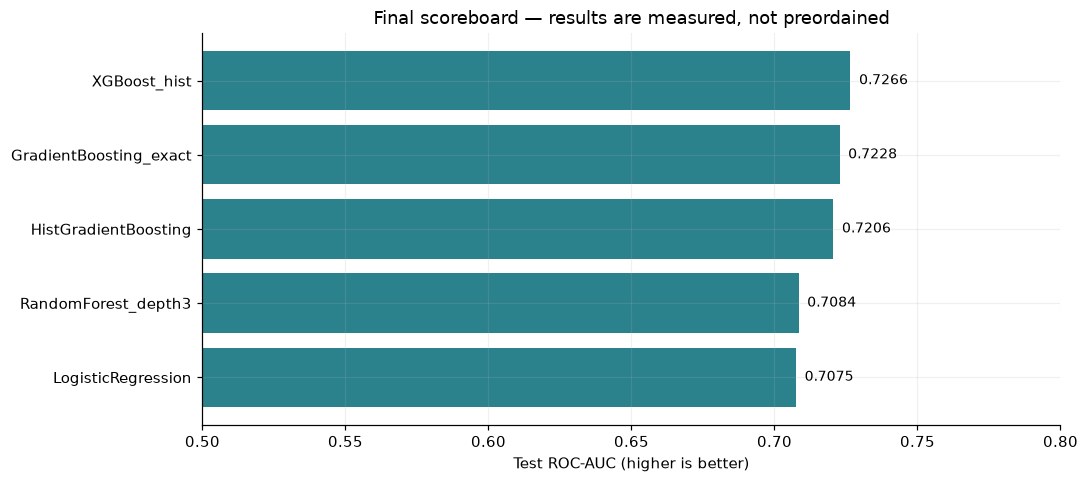

In [57]:
fig,ax=plt.subplots(figsize=(10,4.5))
ft=final_table.sort_values('test_roc_auc')
ax.barh(ft.index,[float(v) for v in ft['test_roc_auc']],color='#2b828d')
ax.set_xlim(.5,max(.8,float(ft['test_roc_auc'].max())+.045))
for i,v in enumerate(ft['test_roc_auc']):ax.text(float(v)+.003,i,f'{float(v):.4f}',va='center',fontsize=9)
ax.set_xlabel('Test ROC-AUC (higher is better)')
ax.set_title('Final scoreboard — results are measured, not preordained')
plt.tight_layout();fig.savefig(OUTPUT/'08_final_scoreboard.png',dpi=160);plt.show()